# Benchmark: CSV vs. Parquet y Lectura Directa en S3 (Lab 20)

**Actividades 7 y 8** — Comparación local con números reales medidos sobre `observations` (5,719,327 filas) y consulta directa sobre `s3://omop-tesis-jhr-2026/curated/synthea/observations/` sin descargar a disco.

## 1. Entorno, hardware y versiones (Actividad 7)

In [1]:
import os
import platform
import shutil
import statistics
import time
from pathlib import Path

import boto3
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import s3fs

def info_cpu() -> str:
    with open("/proc/cpuinfo", encoding="utf-8") as f:
        for linea in f:
            if linea.startswith("model name"):
                return linea.split(":", 1)[1].strip()
    return platform.processor()

ram_gb = (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) / (1024**3)
disco = shutil.disk_usage(Path.cwd())
print(f"Sistema:  {platform.system()} {platform.release()} ({platform.machine()})")
print(f"CPU:      {info_cpu()} ({os.cpu_count()} hilos lógicos)")
print(f"RAM:      {ram_gb:.1f} GiB")
print(f"Disco:    {disco.free / (1024**3):.1f} GiB libres de {disco.total / (1024**3):.1f} GiB")
print(f"Python:   {platform.python_version()}")
print(f"pandas:   {pd.__version__} | pyarrow: {pa.__version__} | duckdb: {duckdb.__version__} | s3fs: {s3fs.__version__} | boto3: {boto3.__version__}")

Sistema:  Linux 7.1.5-76070105-generic (x86_64)
CPU:      Intel(R) Core(TM) i5-14400F (16 hilos lógicos)
RAM:      46.9 GiB
Disco:    1393.8 GiB libres de 1867.8 GiB
Python:   3.12.3
pandas:   3.1.1 | pyarrow: 26.0.1 | duckdb: 2.0.0 | s3fs: 2026.9.0 | boto3: 1.43.117


## 2. Medición en disco y tiempos (CSV vs. Parquet, 5 corridas)

In [2]:
RAIZ_REPO = Path.cwd().resolve().parents[1]
CSV_PATH = RAIZ_REPO / "s10-sql-fundamentals/tu-entrega/data/synthea/csv/observations.csv"
PARQUET_DIR = Path.cwd().resolve() / "datos/curated/synthea/observations"

assert CSV_PATH.is_file(), f"No existe {CSV_PATH}"
assert PARQUET_DIR.is_dir(), f"No existe {PARQUET_DIR}"

bytes_csv = os.path.getsize(CSV_PATH)
archivos_pq = list(PARQUET_DIR.rglob("*.parquet"))
bytes_pq = sum(os.path.getsize(p) for p in archivos_pq)

print(f"CSV en disco:     {bytes_csv / (1024**2):.2f} MiB ({bytes_csv:,} bytes)")
print(f"Parquet en disco: {bytes_pq / (1024**2):.2f} MiB ({bytes_pq:,} bytes en {len(archivos_pq)} archivos)")
print(f"Factor de compresión: {bytes_csv / bytes_pq:.2f}x más pequeño")

CSV en disco:     973.60 MiB (1,020,894,411 bytes)
Parquet en disco: 128.25 MiB (134,482,492 bytes en 110 archivos)
Factor de compresión: 7.59x más pequeño


In [3]:
N_CORRIDAS = 5

def medir(fn, n: int = N_CORRIDAS) -> list[float]:
    """Ejecuta fn n veces con time.perf_counter(); conserva todas las corridas (incluida corrida 1 en frío)."""
    tiempos = []
    for _ in range(n):
        t0 = time.perf_counter()
        _ = fn()
        tiempos.append(time.perf_counter() - t0)
    return tiempos

ESQUEMA_CSV = {
    "PATIENT": "string",
    "ENCOUNTER": "string",
    "CATEGORY": "string",
    "CODE": "string",
    "DESCRIPTION": "string",
    "VALUE": "string",
    "UNITS": "string",
    "TYPE": "string",
}

t_csv_full = medir(lambda: pd.read_csv(CSV_PATH, dtype=ESQUEMA_CSV, parse_dates=["DATE"]))
t_pq_full = medir(lambda: pd.read_parquet(PARQUET_DIR))
t_csv_col = medir(lambda: pd.read_csv(CSV_PATH, usecols=["CODE"], dtype={"CODE": "string"}))
t_pq_col = medir(lambda: pd.read_parquet(PARQUET_DIR, columns=["CODE"]))

print("Nota metodológica: se ejecutan 5 corridas y se conservan todas (incluida la corrida 1 en frío).")
for nombre, t in [
    ("CSV completo", t_csv_full),
    ("Parquet completo", t_pq_full),
    ("CSV 1 columna (CODE)", t_csv_col),
    ("Parquet 1 columna (CODE)", t_pq_col),
]:
    print(f"{nombre:26s} -> mediana={statistics.median(t):.3f}s | min={min(t):.3f}s | max={max(t):.3f}s | corridas={[round(x, 3) for x in t]}")

Nota metodológica: se ejecutan 5 corridas y se conservan todas (incluida la corrida 1 en frío).
CSV completo               -> mediana=3.859s | min=3.748s | max=3.976s | corridas=[3.976, 3.763, 3.748, 3.859, 3.949]
Parquet completo           -> mediana=1.173s | min=1.144s | max=1.239s | corridas=[1.144, 1.239, 1.187, 1.173, 1.169]
CSV 1 columna (CODE)       -> mediana=0.708s | min=0.700s | max=0.748s | corridas=[0.723, 0.748, 0.706, 0.708, 0.7]
Parquet 1 columna (CODE)   -> mediana=0.517s | min=0.466s | max=0.538s | corridas=[0.52, 0.466, 0.487, 0.517, 0.538]


## 3. Tabla resumen y gráfica comparativa

In [4]:
tabla_comparativa = pd.DataFrame([
    {
        "Métrica": "Tamaño en disco (MiB)",
        "CSV": round(bytes_csv / (1024**2), 2),
        "Parquet": round(bytes_pq / (1024**2), 2),
        "Mejora (CSV / Parquet)": f"{bytes_csv / bytes_pq:.1f}x",
    },
    {
        "Métrica": "Leer archivo completo (mediana s, n=5)",
        "CSV": round(statistics.median(t_csv_full), 3),
        "Parquet": round(statistics.median(t_pq_full), 3),
        "Mejora (CSV / Parquet)": f"{statistics.median(t_csv_full) / statistics.median(t_pq_full):.1f}x",
    },
    {
        "Métrica": "Leer 1 columna CODE (mediana s, n=5)",
        "CSV": round(statistics.median(t_csv_col), 3),
        "Parquet": round(statistics.median(t_pq_col), 3),
        "Mejora (CSV / Parquet)": f"{statistics.median(t_csv_col) / statistics.median(t_pq_col):.1f}x",
    },
])
display(tabla_comparativa)

,Métrica,CSV,Parquet,Mejora (CSV / Parquet)
0,Tamaño en disco (MiB),973.600,128.250,7.6x
1,"Leer archivo completo (mediana s, n=5)",3.859,1.173,3.3x
2,"Leer 1 columna CODE (mediana s, n=5)",0.708,0.517,1.4x


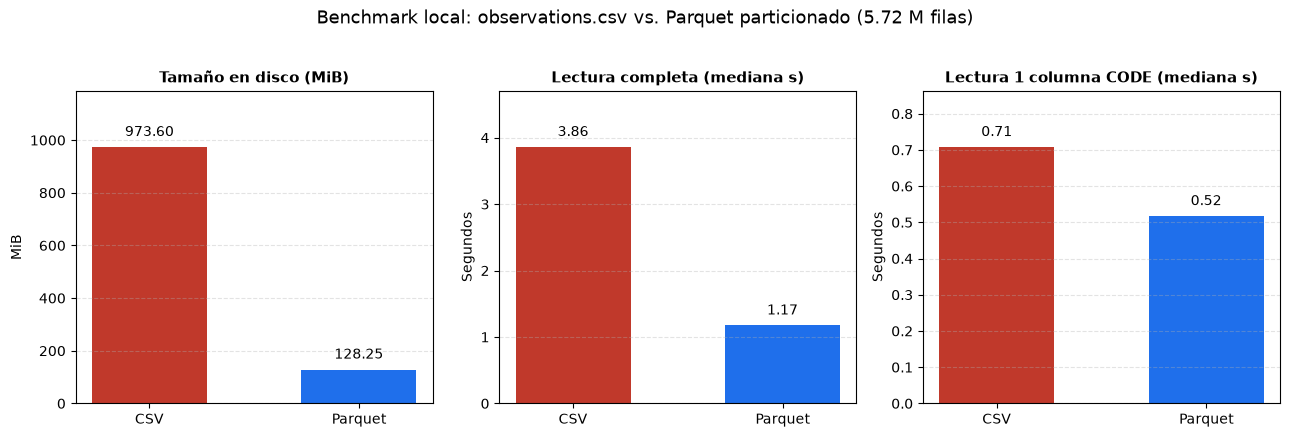

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.2))
paneles = [
    ("Tamaño en disco (MiB)", [bytes_csv / (1024**2), bytes_pq / (1024**2)], "MiB"),
    ("Lectura completa (mediana s)", [statistics.median(t_csv_full), statistics.median(t_pq_full)], "Segundos"),
    ("Lectura 1 columna CODE (mediana s)", [statistics.median(t_csv_col), statistics.median(t_pq_col)], "Segundos"),
]
colores = ["#c0392b", "#1f6feb"]

for ax, (titulo, vals, ylabel) in zip(ejes, paneles):
    barras = ax.bar(["CSV", "Parquet"], vals, color=colores, width=0.55)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals) * 1.22)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + max(vals) * 0.03, f"{v:.2f}", ha="center", va="bottom", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Benchmark local: observations.csv vs. Parquet particionado (5.72 M filas)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

## 4. Lectura directa desde S3 sin descargar (Actividad 8)

Consultamos `s3://omop-tesis-jhr-2026/curated/synthea/observations/` directamente en memoria usando el perfil `tesis`.

In [6]:
RUTA_S3 = "s3://omop-tesis-jhr-2026/curated/synthea/observations/"

# 1. pandas + s3fs: proyección de 4 columnas + filtro por partición (anio == 2025)
archivos_antes = set(Path.cwd().glob("*"))
t0 = time.perf_counter()
df_s3 = pd.read_parquet(
    RUTA_S3,
    columns=["DATE", "CODE", "VALUE", "UNITS"],
    filters=[("anio", "==", 2025)],
    storage_options={"profile": "tesis"},
)
t_pandas_s3 = time.perf_counter() - t0
archivos_despues = set(Path.cwd().glob("*"))

print(f"pandas+s3fs (4 cols, anio=2025): {len(df_s3):,} filas en {t_pandas_s3:.3f} s")
print(f"Archivos creados en directorio actual: {sorted(p.name for p in (archivos_despues - archivos_antes))}")
display(df_s3.head(3))

pandas+s3fs (4 cols, anio=2025): 433,936 filas en 1.602 s
Archivos creados en directorio actual: []


,DATE,CODE,VALUE,UNITS
0,2025-08-07 18:43:33+00:00,8302-2,141.2,cm
1,2025-08-07 18:43:33+00:00,72514-3,2.0,{score}
2,2025-08-07 18:43:33+00:00,29463-7,28.6,kg


In [7]:
# 2. DuckDB + httpfs: comparar consulta SIN filtro de partición vs. CON filtro WHERE anio = 2025
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs; INSTALL aws; LOAD aws;")
con.execute("""
    CREATE OR REPLACE SECRET s3_tesis (
        TYPE s3,
        PROVIDER credential_chain,
        PROFILE 'tesis',
        REGION 'us-east-2'
    );
""")

GLOB_S3 = "s3://omop-tesis-jhr-2026/curated/synthea/observations/*/*.parquet"

t0 = time.perf_counter()
sin_filtro = con.execute(f"""
    SELECT COUNT(*) AS filas, COUNT(DISTINCT PATIENT) AS pacientes
    FROM read_parquet('{GLOB_S3}', hive_partitioning = true)
""").fetchall()
t_duck_sin = time.perf_counter() - t0

t0 = time.perf_counter()
con_filtro = con.execute(f"""
    SELECT COUNT(*) AS filas, COUNT(DISTINCT PATIENT) AS pacientes
    FROM read_parquet('{GLOB_S3}', hive_partitioning = true)
    WHERE anio = 2025
""").fetchall()
t_duck_con = time.perf_counter() - t0

print(f"DuckDB SIN filtro de partición: {sin_filtro[0]} en {t_duck_sin:.3f} s")
print(f"DuckDB CON filtro anio=2025:    {con_filtro[0]} en {t_duck_con:.3f} s ({t_duck_sin / t_duck_con:.1f}x más rápido)")

plan = con.execute(f"""
    EXPLAIN ANALYZE
    SELECT COUNT(*) AS filas, COUNT(DISTINCT PATIENT) AS pacientes
    FROM read_parquet('{GLOB_S3}', hive_partitioning = true)
    WHERE anio = 2025
""").fetchall()
print("\n--- EXPLAIN ANALYZE (WHERE anio = 2025) ---")
for _, texto in plan:
    print(texto)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

DuckDB SIN filtro de partición: (5719327, 5904) en 24.686 s
DuckDB CON filtro anio=2025:    (433936, 5023) en 0.144 s (171.4x más rápido)

--- EXPLAIN ANALYZE (WHERE anio = 2025) ---
┌─────────────────────────────────────┐
│┌───────────────────────────────────┐│
││         HTTPFS HTTP Stats         ││
││                                   ││
││            in: 36.9 KiB           ││
││            out: 0 bytes           ││
││              #HEAD: 0             ││
││              #GET: 1              ││
││              #PUT: 0              ││
││              #POST: 0             ││
││             #DELETE: 0            ││
││            #OPTIONS: 0            ││
│└───────────────────────────────────┘│
└─────────────────────────────────────┘
╭─ Summary ──────────╮
│ Total Time: 0.140s │
╰────────────────────╯
╭─ CTE ──────────────────────────────────────────────────────────────────────────╮
│ CTE Name: __aggregate_cte_7                                                    │
│ Table Index: 7      

### Conclusión (Actividades 7 y 8)

Para las sesiones 21–25 usaría **DuckDB con `httpfs` y `hive_partitioning = true`** como motor principal de consulta sobre S3, porque ejecuta filtros por partición (`anio=`), agregaciones y `JOIN`s directamente sobre los rangos de bytes necesarios sin descargar tablas completas a memoria; reservaría **`pandas` + `s3fs`** para traer ya filtrado y proyectado el subconjunto final de columnas que necesite manipular o graficar en Python.